# League of Legends Match Predictor

### Introduction

League of Legends is a popular multiplayer online battle arena game. It generates extensive data from matches, providing a great opportunity to apply machine learning techniques to real-world scenarios. In this notebook, we build a logistic regression model aimed at predicting the outcomes of League of Legends matches (win / lose). We use the [league_data.xlsx](https://www.kaggle.com/datasets/jakubkrasuski/league-of-legends-match-dataset-2025/) file, which contains detailed game statistics from matches in 2025. It has been published under the licence CC BY 4.0 (Creative Commons Attribution 4.0 International).

Each row of the dataset is one player in one match, and the inputs are statistics recorded at the end of the match (kills, deaths, gold, ...). The model therefore classifies how a finished match went for a player; it does not forecast a match that has not been played yet.

**How the evaluation is designed**
- The data are split by match (`game_id`), so that no match contributes players to both the training and the test set.
- Features are standardized using the training set only.
- The learning rate is chosen on a validation set taken from the training matches; the test set is used once, for the final model.
- At the end we run a set of checks: how much the split matters, a converged reference model, accuracy per role, the rows with a missing role, and whether the `baron_kills` feature helps.

### Setup

In [1]:
# importing necessary libraries & suppressing warnings
import warnings
warnings.filterwarnings('ignore')
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# fixed seeds, so that the results are reproducible
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print('Libraries imported successfully')

Libraries imported successfully


### Reading the excel file

In [ ]:
# path to the Kaggle file
DATA_PATH = "league_data.xlsx"

df = pd.read_excel(DATA_PATH)
print('Dataset loaded successfully')

Dataset loaded successfully


### Getting some information about the dataset

In [3]:
print("Dataset shape:", df.shape)

print("First five rows:")
display(df.head())

print("The number of wins (and losses) in the dataset:\n", df['win'].value_counts())

Dataset shape: (40410, 94)
First five rows:


,game_id,game_start_utc,game_duration,game_mode,game_type,game_version,map_id,platform_id,queue_id,participant_id,...,final_magicPen,final_magicPenPercent,final_magicResist,final_movementSpeed,final_omnivamp,final_physicalVamp,final_power,final_powerMax,final_powerRegen,final_spellVamp
0,3727443167,2025-01-15 14:56:00,1714,CLASSIC,MATCHED_GAME,15.1.649.4112,11,EUN1,420,5,...,0,0,48,385,0,0,799,1134,147,0
1,3726377460,2025-01-13 10:50:00,1300,CLASSIC,MATCHED_GAME,15.1.648.3927,11,EUN1,420,5,...,0,0,38,390,0,0,970,970,105,0
2,3729643655,2025-01-19 18:15:00,2019,CLASSIC,MATCHED_GAME,15.1.649.4112,11,EUN1,420,2,...,0,0,121,431,0,0,10000,10000,0,0
3,3729915593,2025-01-20 01:27:00,1625,CLASSIC,MATCHED_GAME,15.1.649.4112,11,EUN1,420,8,...,12,0,47,380,0,0,1122,1596,37,0
4,3729901665,2025-01-20 00:40:00,1542,CLASSIC,MATCHED_GAME,15.1.649.4112,11,EUN1,420,10,...,0,0,40,534,0,0,1025,1025,109,0


The number of wins (and losses) in the dataset:
 win
True     20220
False    20190
Name: count, dtype: int64


In [4]:
print("\nDataFrame Info:")
print(df.info())


DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 40410 entries, 0 to 40409
Data columns (total 94 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   game_id                                40410 non-null  int64         
 1   game_start_utc                         40410 non-null  datetime64[us]
 2   game_duration                          40410 non-null  int64         
 3   game_mode                              40410 non-null  str           
 4   game_type                              40410 non-null  str           
 5   game_version                           40410 non-null  str           
 6   map_id                                 40410 non-null  int64         
 7   platform_id                            40410 non-null  str           
 8   queue_id                               40410 non-null  int64         
 9   participant_id                         40410 non-null  

### Cleaning the data

The features of the model are listed first, because only they matter for the cleaning. `baron_kills` (the number of Baron Nashor kills credited to the player) is included as an *objective* statistic: unlike kills or gold it describes the team's progress towards winning. It is rare (most players have 0), so we also check below whether it actually helps.

Dropping every row that has a gap in *any* of the 94 columns would remove about 83% of the records, because several columns we never use (flex rank, solo rank, ...) are often empty. Instead we only drop rows where one of our defined features is missing.

In [5]:
# the features used by the model
features = ['kills', 'deaths', 'assists', 'gold_earned', 'total_damage_dealt',
            'wards_placed', 'wards_killed', 'vision_score', 'baron_kills']

# checking for missing values
missingValues = df.isnull().sum()
print("Missing values per column:")
print(missingValues[missingValues > 0])

# dropping only the rows where one of our features is missing
n_before = len(df)
df = df.dropna(subset=features).copy()
print(f"\nRows kept: {len(df)} of {n_before}")

Missing values per column:
summoner_name                             2308
team_position                             9748
solo_tier                                12544
solo_rank                                12544
solo_lp                                  12544
solo_wins                                12544
solo_losses                              12544
flex_tier                                30047
flex_rank                                30047
flex_lp                                  30047
flex_wins                                30047
flex_losses                              30047
champion_mastery_level                      30
champion_mastery_points                     30
champion_mastery_lastPlayTime               30
champion_mastery_lastPlayTime_utc           30
champion_mastery_pointsSinceLastLevel       30
champion_mastery_pointsUntilNextLevel       30
champion_mastery_tokensEarned               30
dtype: int64

Rows kept: 40410 of 40410


### Preparing the model inputs

In [6]:
X = df[features]
y = df['win'].astype(int)          # the target should be numeric, not boolean
groups = df['game_id'].values      # which match each row (player) belongs to

display(X.head())
display(y.head())
print("X:", X.shape, "| y:", y.shape, "| matches:", len(set(groups)))
print("\nPlayers per match in the data:")
print(df.groupby('game_id').size().describe())

,kills,deaths,assists,gold_earned,total_damage_dealt,wards_placed,wards_killed,vision_score,baron_kills
0,0,3,22,8477,22110,21,6,50,0
1,1,6,2,5251,7746,21,7,43,0
2,11,11,11,12570,249727,21,1,47,1
3,1,11,3,9276,126567,10,3,20,0
4,1,4,3,6080,18160,26,7,67,0


0    1
1    0
2    0
3    0
4    0
Name: win, dtype: int64

X: (40410, 9) | y: (40410,) | matches: 4044

Players per match in the data:
count    4044.000000
mean        9.992582
std         0.192474
min         5.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        10.000000
dtype: float64


### Splitting the data (by match)

A match has up to 10 players: the 5 teammates share the same result and the 5 opponents have the opposite one, and their statistics are correlated (same game length, same snowball). If the rows are split at random, some players of a match end up in the training set and others in the test set, so the test score is slightly optimistic and its uncertainty is underestimated.

`GroupShuffleSplit` shuffles *matches* instead of rows: 80% of the matches go to training, 20% to testing, and all players of a match stay on the same side. The checks below confirm that no match appears on both sides.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
test_roles = df['team_position'].iloc[test_idx].values   # kept for the per-role check at the end

# sanity checks
overlap = set(groups[train_idx]) & set(groups[test_idx])
print("matches in both sets:", len(overlap))               # must be 0
print("rows    train/test:", len(X_train), len(X_test))
print("matches train/test:", len(set(groups[train_idx])), len(set(groups[test_idx])))
assert len(overlap) == 0

# standardizing the features: fitted on the training data only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# conversion to torch tensors
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

matches in both sets: 0
rows    train/test: 32325 8085
matches train/test: 3235 809


### Logistic Regression Model

In [8]:
# defining the logistic regression model class:
class logistic_regression(nn.Module):
    def __init__(self, n_inputs):
        super(logistic_regression, self).__init__()
        self.linear = nn.Linear(n_inputs, 1)

    # prediction
    def forward(self, x):
        yhat = torch.sigmoid(self.linear(x))
        return yhat

input_dim = X_train_t.shape[1]
print("The number of inputs: ", input_dim)

The number of inputs:  9


In [9]:
# helper functions, so that every model below is trained and scored in exactly the same way
def train_model(X, y, lr=0.01, weight_decay=0.0, epochs=1000, log_every=None, seed=SEED):
    torch.manual_seed(seed)                      # same initial weights for every run
    m = logistic_regression(X.shape[1])
    criterion = nn.BCELoss()
    # L2 regularisation (weight decay) is applied to the weights, not to the bias
    optimizer = optim.SGD([{'params': m.linear.weight, 'weight_decay': weight_decay},
                           {'params': m.linear.bias, 'weight_decay': 0.0}], lr=lr)
    for epoch in range(epochs):
        m.train()                                # training mode on
        optimizer.zero_grad()                    # zero the gradients
        loss = criterion(m(X), y)                # predictions and loss
        loss.backward()                          # backpropagation
        optimizer.step()                         # update the weights
        if log_every and (epoch + 1) % log_every == 0:
            print(f'Epoch [{epoch + 1}/{epochs}], Train loss: {loss.item():.4f}')
    return m

def accuracy(m, X, y):
    m.eval()
    with torch.no_grad():                        # no gradients during evaluation
        return ((m(X) > 0.5).float() == y).float().mean().item()   # threshold 0.5

### Model Training (baseline: learning rate 0.01, 1000 epochs)

In [10]:
model_base = train_model(X_train_t, y_train_t, lr=0.01, epochs=1000, log_every=100)

print("The accuracy of the training set:", round(accuracy(model_base, X_train_t, y_train_t), 4))
print("The accuracy of the test set:    ", round(accuracy(model_base, X_test_t, y_test_t), 4))

Epoch [100/1000], Train loss: 0.6846
Epoch [200/1000], Train loss: 0.6496
Epoch [300/1000], Train loss: 0.6243
Epoch [400/1000], Train loss: 0.6054
Epoch [500/1000], Train loss: 0.5907
Epoch [600/1000], Train loss: 0.5792
Epoch [700/1000], Train loss: 0.5701
Epoch [800/1000], Train loss: 0.5627
Epoch [900/1000], Train loss: 0.5566
Epoch [1000/1000], Train loss: 0.5516
The accuracy of the training set: 0.7506
The accuracy of the test set:     0.7459


### Model Optimization using L2 regularization (Ridge Regression)

L2 regularization helps when a model overfits. With 9 features and tens of thousands of rows, it is not expected to help here; it is shown for comparison only and is not used to select the final model.

In [11]:
model_l2 = train_model(X_train_t, y_train_t, lr=0.01, weight_decay=0.01, epochs=1000, log_every=100)

print("The accuracy of the training set with L2:", round(accuracy(model_l2, X_train_t, y_train_t), 4))
print("The accuracy of the test set with L2:    ", round(accuracy(model_l2, X_test_t, y_test_t), 4))

Epoch [100/1000], Train loss: 0.6842
Epoch [200/1000], Train loss: 0.6494
Epoch [300/1000], Train loss: 0.6245
Epoch [400/1000], Train loss: 0.6059
Epoch [500/1000], Train loss: 0.5917
Epoch [600/1000], Train loss: 0.5806
Epoch [700/1000], Train loss: 0.5718
Epoch [800/1000], Train loss: 0.5647
Epoch [900/1000], Train loss: 0.5589
Epoch [1000/1000], Train loss: 0.5541
The accuracy of the training set with L2: 0.7508
The accuracy of the test set with L2:     0.7453


### Hyperparameter Tuning (best learning rate)

The learning rate is chosen on a validation set, not on the test set. The validation set is taken from the training matches (again split by match). Every learning rate is trained for the same 1000 epochs, so that a small learning rate is not penalised just for converging slowly.

In [12]:
# a validation set inside the training data, split by match
groups_train = groups[train_idx]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, val_idx = next(gss_val.split(X_train_s, groups=groups_train))
tr_idx, val_idx = torch.as_tensor(tr_idx), torch.as_tensor(val_idx)

X_tr, y_tr = X_train_t[tr_idx], y_train_t[tr_idx]
X_val, y_val = X_train_t[val_idx], y_train_t[val_idx]

learningRates = [0.01, 0.05, 0.1, 0.5]
val_accuracies = {}
for lrn in learningRates:
    m = train_model(X_tr, y_tr, lr=lrn, epochs=1000)
    val_accuracies[lrn] = accuracy(m, X_val, y_val)
    print(f"learning rate {lrn:<5}: validation accuracy {val_accuracies[lrn]:.4f}")

# the best learning rate according to the validation set
best_lr = max(val_accuracies, key=val_accuracies.get)
print(f"\nthe learning rate {best_lr} has the highest validation accuracy: {val_accuracies[best_lr]:.4f}")

learning rate 0.01 : validation accuracy 0.7564
learning rate 0.05 : validation accuracy 0.7640
learning rate 0.1  : validation accuracy 0.7638
learning rate 0.5  : validation accuracy 0.7646

the learning rate 0.5 has the highest validation accuracy: 0.7646


### Final model

The model is trained again on all training rows with the chosen learning rate and evaluated on the test set, once.

In [13]:
model_final = train_model(X_train_t, y_train_t, lr=best_lr, epochs=1000)

train_acc = accuracy(model_final, X_train_t, y_train_t)
test_acc = accuracy(model_final, X_test_t, y_test_t)
print(f"The accuracy of the training set: {train_acc:.4f}")
print(f"The accuracy of the test set:     {test_acc:.4f}")

The accuracy of the training set: 0.7593
The accuracy of the test set:     0.7540


### Visualization and Interpretation (final model, test set)

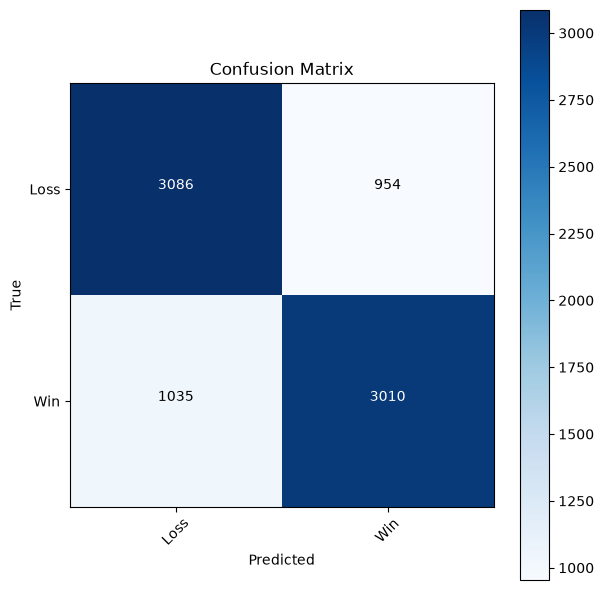

Classification Report:
               precision    recall  f1-score   support

        Loss       0.75      0.76      0.76      4040
         Win       0.76      0.74      0.75      4045

    accuracy                           0.75      8085
   macro avg       0.75      0.75      0.75      8085
weighted avg       0.75      0.75      0.75      8085



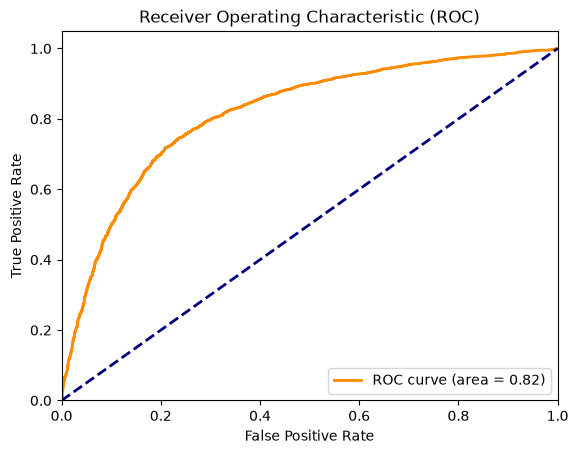

In [14]:
model_final.eval()
with torch.no_grad():
    yhat_test = model_final(X_test_t).numpy().ravel()      # predicted probabilities of a win
y_true = y_test.values
y_pred = (yhat_test > 0.5).astype(int)

# confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = range(2)
plt.xticks(tick_marks, ['Loss', 'Win'], rotation=45)
plt.yticks(tick_marks, ['Loss', 'Win'])

thresh = cm.max() / 2
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

# classification report
print("Classification Report:\n", classification_report(y_true, y_pred, target_names=['Loss', 'Win']))

# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, yhat_test)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

### Feature Importance

The features were standardized, so the weights of the linear layer are comparable: a positive weight pushes the prediction towards a win, a negative weight towards a loss.

              Feature  Importance
2             assists    0.980855
0               kills    0.594257
3         gold_earned    0.359391
8         baron_kills    0.249871
5        wards_placed    0.225157
4  total_damage_dealt    0.027749
7        vision_score   -0.046586
6        wards_killed   -0.090382
1              deaths   -1.591001


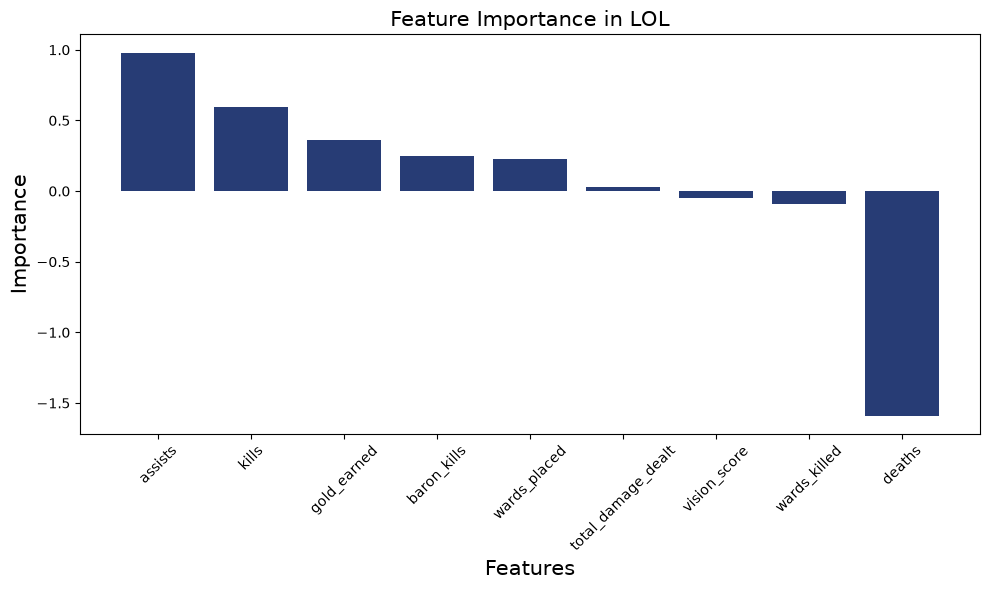

In [15]:
# extracting the weights of the linear layer
weights = model_final.linear.weight.data.numpy().flatten()

# creating a DataFrame for feature importance
feature_importance = pd.DataFrame({'Feature': features, 'Importance': weights})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

# plotting feature importance
plt.figure(figsize=(10, 6))
plt.bar(feature_importance['Feature'], feature_importance['Importance'], color="#273c75")
plt.xlabel('Features', fontsize=15)
plt.ylabel('Importance', fontsize=15)
plt.title('Feature Importance in LOL', fontsize=15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Checks

The cells below test how much the conclusions depend on the choices made above.

### Check 1: how much did splitting by match matter?

Same model (standardization + logistic regression, as one sklearn pipeline so that the scaler is fitted on the training folds only), evaluated with 5-fold cross-validation twice: with rows shuffled at random, and with whole matches kept together. The difference between the two is the size of the same-match leakage.

In [16]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

random_cv = cross_val_score(pipe, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=SEED))
group_cv = cross_val_score(pipe, X, y, cv=GroupKFold(n_splits=5), groups=groups)

print(f"random 5-fold:           {random_cv.mean():.4f} ± {random_cv.std():.4f}")
print(f"grouped-by-match 5-fold: {group_cv.mean():.4f} ± {group_cv.std():.4f}")
print(f"difference (leakage):    {random_cv.mean() - group_cv.mean():+.4f}")

random 5-fold:           0.7579 ± 0.0025
grouped-by-match 5-fold: 0.7584 ± 0.0077
difference (leakage):    -0.0004


### Check 2: is the PyTorch model converged?

A logistic regression has a single optimum. sklearn finds it exactly; gradient descent only approaches it, so a PyTorch model that is clearly below sklearn has not finished training.

In [17]:
sk = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
print(f"sklearn (converged) test accuracy: {sk.score(X_test_s, y_test):.4f}")
print(f"PyTorch final model test accuracy: {test_acc:.4f}")

sklearn (converged) test accuracy: 0.7539
PyTorch final model test accuracy: 0.7540


### Check 3: accuracy per role

`team_position` is the role a player played. It is empty for some players (shown as `NaN`); these rows are reported as their own group.

In [18]:
print(pd.DataFrame({'role': test_roles, 'correct': y_pred == y_true})
        .groupby('role', dropna=False)['correct']
        .agg(accuracy='mean', n='size'))

         accuracy     n
role                   
BOTTOM   0.772245  1225
JUNGLE   0.839869  1224
MIDDLE   0.769608  1224
TOP      0.758170  1224
UTILITY  0.763072  1224
NaN      0.671079  1964


### Check 4: what are the rows with a missing role?

If their accuracy is much lower than the rest, we need to know whether they are different games (short games, leavers, another queue) or only different players.

In [19]:
d = df.assign(role_missing=df['team_position'].isna())

print("Median statistics:")
print(d.groupby('role_missing')[['game_duration', 'kills', 'deaths', 'assists', 'gold_earned',
                                  'damage_dealt_to_turrets']].median())
print("\nShare of wins:")
print(d.groupby('role_missing')['win'].mean())
print("\nQueue ids:")
print(d.groupby('role_missing')['queue_id'].value_counts())
print("\nShare of players with a missing role, per match (0.0 = none, 1.0 = the whole match):")
print(d.groupby('game_id')['role_missing'].mean().round(1).value_counts().sort_index())

Median statistics:
              game_duration  kills  deaths  assists  gold_earned  \
role_missing                                                       
False                1714.0    5.0     6.0      7.0      10995.5   
True                 1218.0   10.0    11.0     25.0      13897.5   

              damage_dealt_to_turrets  
role_missing                           
False                          2326.0  
True                            954.0  

Share of wins:
role_missing
False    0.500783
True     0.499077
Name: win, dtype: float64

Queue ids:
role_missing  queue_id
False         420         21898
              440          3988
              400          3418
              480          1248
              490            50
              700            30
              890            25
              870             5
True          450          9730
              420            12
              440             2
              400             2
              480             2
Name: 

### Check 5: does `baron_kills` help?

First, how often is it non-zero? Then the same grouped 5-fold cross-validation with and without the feature. The comparison is paired: both versions see exactly the same folds.

In [20]:
print("baron_kills value counts:")
print(df['baron_kills'].value_counts().sort_index())

features_without = [f for f in features if f != 'baron_kills']
cv = GroupKFold(n_splits=5)
scores_without = cross_val_score(pipe, df[features_without], y, cv=cv, groups=groups)
scores_with = cross_val_score(pipe, df[features], y, cv=cv, groups=groups)

print(f"\nwithout baron_kills: {scores_without.mean():.4f} ± {scores_without.std():.4f}")
print(f"with baron_kills:    {scores_with.mean():.4f} ± {scores_with.std():.4f}")
diff = scores_with - scores_without
print(f"paired difference per fold: {np.round(diff, 4)}  (mean {diff.mean():+.4f})")

baron_kills value counts:
baron_kills
0    38436
1     1825
2      144
3        5
Name: count, dtype: int64

without baron_kills: 0.7551 ± 0.0079
with baron_kills:    0.7584 ± 0.0077
paired difference per fold: [0.0037 0.0031 0.003  0.0047 0.0016]  (mean +0.0032)


### Saving (and loading) the model

In [21]:
# saving the model
torch.save(model_final.state_dict(), 'logisticRegModel.pth')
print("Model saved successfully.")

# loading it again and checking that it behaves identically
loaded_model = logistic_regression(input_dim)
loaded_model.load_state_dict(torch.load('logisticRegModel.pth'))
loaded_model.eval()
print("Loaded model test accuracy:", round(accuracy(loaded_model, X_test_t, y_test_t), 4),
      "| same as the saved model:", accuracy(loaded_model, X_test_t, y_test_t) == test_acc)

# note: to use the model on new data, the fitted scaler is needed as well (e.g. joblib.dump(scaler, 'scaler.joblib'))

Model saved successfully.
Loaded model test accuracy: 0.754 | same as the saved model: True


# Conclusions

In [22]:
print(f"Final model (PyTorch logistic regression, learning rate {best_lr}, split by match)")
print(f"  test accuracy:          {test_acc:.4f}")
print(f"  test ROC AUC:           {roc_auc:.4f}")
print(f"  sklearn reference:      {sk.score(X_test_s, y_test):.4f}")
print(f"  5-fold grouped CV:      {group_cv.mean():.4f} ± {group_cv.std():.4f}")
print(f"  effect of the split:    random minus grouped CV = {random_cv.mean() - group_cv.mean():+.4f}")
print(f"  baron_kills (paired):   {diff.mean():+.4f} accuracy per fold")

Final model (PyTorch logistic regression, learning rate 0.5, split by match)
  test accuracy:          0.7540
  test ROC AUC:           0.8153
  sklearn reference:      0.7539
  5-fold grouped CV:      0.7584 ± 0.0077
  effect of the split:    random minus grouped CV = -0.0004
  baron_kills (paired):   +0.0032 accuracy per fold


In this notebook we built a logistic regression model to classify the outcome of League of Legends matches from end-of-match player statistics, using the League of Legends Match Dataset 2025. We went through data loading, cleaning, a split by match (to avoid same-match leakage), standardization fitted on the training set only, training in PyTorch, L2 regularization, learning-rate selection on a validation set, evaluation with a confusion matrix, classification report and ROC curve, and an analysis of the learned weights.

The checks quantify how far the numbers can be trusted: the effect of the split strategy, the gap to a converged reference model, the differences between roles (and the group of players with no recorded role), and the contribution of the `baron_kills` feature. The model uses only individual statistics; adding team-level or objective information (turret damage, dragons, game duration, role) would be the natural next step.